# Лабораторная работа № 2.4
---
«Выявление скрытых переменных на основе метода PCA»

Рязанцев Георгий Борисович

## 1. Импорт библиотек, загрузка данных и стандартизация

In [1]:
#импортируем необходимые библиотеки
import pandas as pd
import seaborn as sns
from sklearn import preprocessing
from sklearn.decomposition import PCA
import pylab as plt


#загрузим данные
data = pd.read_csv('Rural_prices.csv', sep=";", decimal=",")

#выберем переменные для модели
x1 = data.drop('sale price', axis=1)
y1 = data['sale price']

In [2]:
# Дополнительно (в методичке отсутствует): сохраняем исходную таблицу признаков и их названия,
# потому что стандартизация ниже заменяет x1 массивом NumPy без названий столбцов
x1_raw = x1.copy()
feature_names = x1.columns.tolist()

print('Данные:', data.shape, '| признаки x1:', x1.shape, '| целевая y1:', y1.shape)
print('Признаки:', feature_names)
print('Пропусков:', int(data.isna().sum().sum()))

Данные: (546, 12) | признаки x1: (546, 11) | целевая y1: (546,)
Признаки: ['lot size', '#bedroom', '#bath', '#stories', 'driveway', 'rec room', 'basement', 'gas', 'air cond', '#garage', 'desire loc']
Пропусков: 0


In [3]:
# Стандартизация данных
x1 = preprocessing.StandardScaler().fit(x1).transform(x1)

In [4]:
# Дополнительно: проверка стандартизации (формула 2.4: z = (x - среднее) / стандартное отклонение)
print('Тип x1 после стандартизации:', type(x1).__name__, x1.shape)
print('Максимальное |среднее| по столбцам:', abs(x1.mean(axis=0)).max().round(12))
print('Стандартные отклонения столбцов:', x1.std(axis=0).round(6).tolist())

Тип x1 после стандартизации: ndarray (546, 11)
Максимальное |среднее| по столбцам: 0.0
Стандартные отклонения столбцов: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


**Результат и отличия от рис. 2.31.** Код совпадает с рис. 2.31; данные те же, что в работах 2.3 и 2.6: 546 наблюдений, 11 признаков и целевая переменная `sale price`.

- **Что делает стандартизация.** `StandardScaler` реализует формулу (2.4) методички: из каждого признака вычитается его среднее и результат делится на стандартное отклонение (с делением на $n$, а не на $n-1$). Проверка выше: средние равны 0, отклонения — 1. Без стандартизации первая главная компонента определялась бы признаком `lot size` (значения порядка тысяч), а не структурой связей между признаками, так как PCA чувствителен к масштабу.
- **Целевая переменная в PCA не участвует.** `sale price` вынесена в `y1` и не стандартизируется: PCA ищет структуру только среди 11 признаков (метод «без учителя»), а `y1` используется позже для прогноза.
- **Отличие в работе с `x1`.** Строка `x1 = ...fit(x1).transform(x1)` заменяет таблицу `pandas` массивом NumPy, названия столбцов теряются. На ход работы это не влияет (PCA и `GaussianNB` принимают массив), но названия нужны для таблицы компонент (раздел 3), где методичка задаёт их списком вручную. Поэтому исходная таблица сохранена в `x1_raw`, а названия — в `feature_names`.
- Библиотека `seaborn` на рис. 2.31 импортируется, но дальше нигде не используется; `pylab` оставлен как в методичке (он подтягивает `matplotlib.pyplot`).

## 2. Анализ главных компонент и график каменистой осыпи

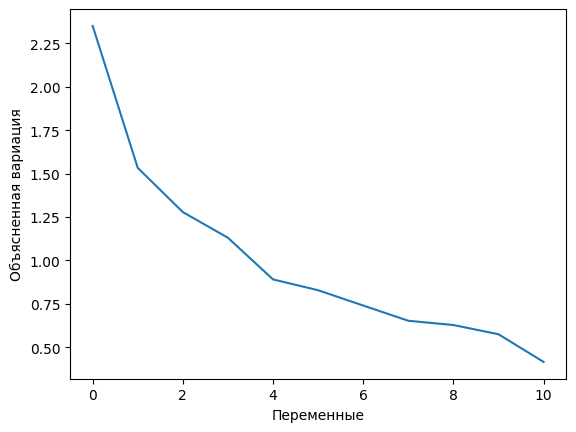

In [5]:
# Создание экземпляра класса анализа главных компонент
model = PCA()

# Применение PCA к свободным переменным для поиска возможности свертки их в меньшее количество переменных
# Результат преобразуется в массив для использования вновь созданных данных
results = model.fit(x1)
Z = results.transform(x1)

# График объясняемой дисперсии переменных: в данном случае график каменистой осыпи
plt.plot(results.explained_variance_)
plt.xlabel('Переменные')
plt.ylabel('Объясненная вариация')
# Отображение графика
plt.show()

In [6]:
# Дополнительно: доли объяснённой дисперсии (график выше показывает собственные значения, а не проценты)
import numpy as np

pca_table = pd.DataFrame({
    'Собственное значение': results.explained_variance_,
    'Доля, %': results.explained_variance_ratio_ * 100,
    'Накопленная доля, %': results.explained_variance_ratio_.cumsum() * 100,
}, index=['PC%d' % i for i in range(1, len(results.explained_variance_) + 1)])
print(pca_table.round(2).to_string())
print()
print('Сумма собственных значений:', results.explained_variance_.sum().round(3), '(число признаков:', x1.shape[1], ')')
print('Компоненты с собственным значением > 1 (критерий Кайзера):', int((results.explained_variance_ > 1).sum()))

# Проверка соответствия описанию в методичке (ковариационная матрица -> собственные значения)
eig = np.sort(np.linalg.eigvalsh(np.cov(x1.T)))[::-1]
print('Собственные значения ковариационной матрицы совпадают с explained_variance_:', np.allclose(eig, results.explained_variance_))
print('Форма Z (новые координаты):', Z.shape)

      Собственное значение  Доля, %  Накопленная доля, %
PC1                   2.35    21.33                21.33
PC2                   1.53    13.91                35.24
PC3                   1.28    11.60                46.84
PC4                   1.13    10.26                57.09
PC5                   0.89     8.08                65.17
PC6                   0.83     7.51                72.69
PC7                   0.74     6.71                79.40
PC8                   0.65     5.92                85.32
PC9                   0.63     5.70                91.02
PC10                  0.57     5.21                96.23
PC11                  0.42     3.77               100.00

Сумма собственных значений: 11.02 (число признаков: 11 )
Компоненты с собственным значением > 1 (критерий Кайзера): 4
Собственные значения ковариационной матрицы совпадают с explained_variance_: True
Форма Z (новые координаты): (546, 11)


**Результат и отличия от рис. 2.32–2.33.** Код совпадает с рис. 2.32. Расхождения:

- **Подписи осей добавлены.** На рис. 2.33 у осей есть подписи («Объясненная вариация», «Переменные»), а в коде рис. 2.32 их нет; строки `plt.xlabel` и `plt.ylabel` добавлены. По оси x компоненты нумеруются с нуля (0 — первая компонента).
- **По оси y — не проценты, а собственные значения.** `explained_variance_` — собственные значения ковариационной матрицы; при стандартизации их сумма примерно равна числу признаков: 11,02 (точно 11 · n/(n − 1): `StandardScaler` делит на $n$, а PCA — на $n-1$; на доли это не влияет). Доли в процентах даёт `explained_variance_ratio_` (таблица выше). Совпадение собственных значений с результатом `np.linalg.eigvalsh(np.cov(...))` подтверждает описание шагов PCA в теории методички (ковариационная матрица → собственные значения → новые координаты); внутри `sklearn` для этого используется сингулярное разложение, результат тот же.
- **Проценты в тексте методички не согласуются с её рисунком.** Текст называет доли 25 %, 16 %, 13 %, 12 %, 9 %, 8 %, 7,5 %, 7 %. По ординатам рис. 2.33 первая компонента имеет собственное значение ≈ 2,35, то есть ≈ 2,35 / 11 ≈ 21 % дисперсии, вторая ≈ 1,54 / 11 ≈ 14 %, третья ≈ 11,6 %. Верными нужно считать значения из таблицы выше.
- **Результат нашего запуска совпадает с рисунком методички, а не с её текстом.** Доли: PC1 — 21,33 %, PC2 — 13,91 %, PC3 — 11,60 %, PC4 — 10,26 %, PC5 — 8,08 %, PC6 — 7,51 %, PC7 — 6,71 %, PC8 — 5,92 %, PC9 — 5,70 %, PC10 — 5,21 %, PC11 — 3,77 %. Собственные значения (2,35; 1,53; 1,28; 1,13; 0,89; …) совпадают с ординатами рис. 2.33, а проценты из текста методички завышены (25 вместо 21, 16 вместо 14, 13 вместо 12 и т. д.).
- **Сколько компонент достаточно.** Первые 4 компоненты объясняют 57,1 % дисперсии, первые 5 — 65,2 %, первые 8 — 85,3 %. Критерий Кайзера (собственное значение > 1) оставляет **4** компоненты (у пятой 0,89). Резкий излом графика происходит на 4–5-й компоненте, то есть утверждение методички «первые 5 переменных содержат большую часть информации» верно лишь отчасти: 5 компонент дают около двух третей дисперсии, треть остаётся в остальных шести. Если нужно сохранить не менее 80–90 % информации, требуется 7–9 компонент.

## 3. Компоненты PCA во фрейме данных

In [7]:
pd.DataFrame(results.components_, columns=list(
    ['lot size',
     '#bedroom',
     '#bath',
     '#stories',
     'driveway',
     'rec room',
     'basement',
     'gas',
     'air cond',
     '#garage',
     'desire loc']))

,lot size,#bedroom,#bath,#stories,driveway,rec room,basement,gas,air cond,#garage,desire loc
0,0.392165,0.366846,0.385501,0.332323,0.260635,0.251864,0.174452,0.000677,0.346017,0.314548,0.268537
1,0.159181,-0.330685,-0.251365,-0.486772,0.209912,0.364192,0.489260,-0.094980,-0.093307,0.072276,0.355179
2,-0.368968,0.293716,0.237495,0.057411,-0.442992,0.401912,0.466119,0.076738,-0.054656,-0.365077,-0.026347
3,0.100700,0.087177,0.164832,-0.183413,-0.004691,-0.054802,0.091838,0.770142,-0.422068,0.344630,-0.141282
4,0.164573,-0.010785,0.123793,-0.346933,-0.477762,-0.008236,0.106873,-0.316418,0.237737,0.488430,-0.449626
5,0.075060,0.333313,0.122560,-0.150674,-0.265440,-0.490378,0.058812,-0.290586,-0.382084,0.062463,0.544818
6,0.027216,-0.140571,-0.249961,-0.014633,-0.457046,-0.143170,-0.054817,0.440591,0.561857,-0.000186,0.417860
7,0.610147,-0.130284,0.150181,-0.038860,-0.320642,0.373207,-0.418914,-0.003133,-0.235757,-0.333577,0.047267
8,-0.082560,-0.496711,0.745150,-0.169993,0.109703,-0.264665,0.076910,0.033083,0.163073,-0.206478,0.063227
9,-0.439705,-0.309442,0.140059,0.224517,-0.162354,0.355909,-0.316631,-0.100430,-0.205550,0.494318,0.301509


In [8]:
# Дополнительно: те же компоненты с подписями строк и проверка, что список названий в коде совпадает с таблицей данных
loadings = pd.DataFrame(results.components_, columns=feature_names, index=['PC%d' % i for i in range(1, 12)])
print('Список названий в ячейке выше совпадает с feature_names:',
      list(['lot size', '#bedroom', '#bath', '#stories', 'driveway', 'rec room', 'basement', 'gas', 'air cond', '#garage', 'desire loc']) == feature_names)
print()
# признаки с наибольшими по модулю весами в первых четырёх компонентах
for pc in ['PC1', 'PC2', 'PC3', 'PC4']:
    top = loadings.loc[pc].abs().sort_values(ascending=False).head(3).index
    print(pc, ':', ', '.join('%s (%.2f)' % (f, loadings.loc[pc, f]) for f in top))

Список названий в ячейке выше совпадает с feature_names: True

PC1 : lot size (0.39), #bath (0.39), #bedroom (0.37)
PC2 : basement (0.49), #stories (-0.49), rec room (0.36)
PC3 : basement (0.47), driveway (-0.44), rec room (0.40)
PC4 : gas (0.77), air cond (-0.42), #garage (0.34)


**Результат и отличия.** Код совпадает с методичкой (рис. на стр. 47); строки таблицы — главные компоненты (в порядке убывания объяснённой дисперсии), столбцы — исходные признаки, значения — веса (нагрузки) признаков в линейной комбинации. Названия столбцов в методичке заданы вручную, дополнительная ячейка проверяет, что их порядок совпадает с порядком столбцов `x1`: если бы порядок не совпал, компоненты были бы подписаны неверно. Знак у компоненты не несёт смысла (компонента с обратными знаками эквивалентна), значимы относительные величины весов.

**Результат (интерпретация нагрузок).** 
- **PC1 (21,3 %)** — все веса положительны и сопоставимы: `lot size` (0,39), `#bath` (0,39), `#bedroom` (0,37), `#stories` (0,33), `air cond`, `#garage`. Это общий фактор «размер и благоустроенность дома»: чем больше дом и участок, тем выше значение компоненты.
- **PC2 (13,9 %)** — противопоставление `#stories` (−0,49) и `#bedroom` (−0,33) признакам `basement` (0,49), `rec room` (0,36), `desire loc` (0,36): грубо, «дом с подвалом и комнатой отдыха в хорошем месте» против «многоэтажного дома».
- **PC3 (11,6 %)** — `basement` (0,47) и `rec room` (0,40) против `driveway` (−0,44), `lot size` (−0,37) и `#garage` (−0,37): «подвальный» тип против «наземного» с подъездом, участком и гаражом.
- **PC4 (10,3 %)** — почти целиком признак `gas` (0,77): компонента отражает редкий признак (газ есть лишь у ≈ 5 % домов), а не общий фактор.

Интерпретации содержательные, а не строгие: из компонент 2–4 следуют лишь относительные веса, и их названия — наша трактовка.

## 4. Прогноз до применения PCA (наивный байесовский классификатор)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix
import pylab as plt
# Выбор наивного классификатора Байеса; для оценки вероятности применяется гауссово распределение
gnb = GaussianNB()
# Подгонка данных
fit = gnb.fit(x1, y1)
# Прогнозирование для неизвестных данных
pred = fit.predict(x1)
# Изучение матрицы несоответствий
print(confusion_matrix(pred,y1))
# Подсчет правильно классифицированных случаев
print(confusion_matrix(pred,y1).trace())

[[0 0 0 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 ...
 [0 0 0 ... 1 0 0]
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 0 0 1]]
196


In [10]:
# Дополнительно: что на самом деле классифицирует модель
n_classes = y1.nunique()
correct_raw = int(confusion_matrix(pred, y1).trace())
print('Число различных значений sale price (число «классов»):', n_classes)
print('Классов, встречающихся в данных ровно один раз:', int((y1.value_counts() == 1).sum()))
print('Размер матрицы несоответствий:', confusion_matrix(pred, y1).shape)
print()
print('Правильных прогнозов: %d из %d (%.1f %%)' % (correct_raw, len(y1), 100 * correct_raw / len(y1)))
print('Для сравнения: прогноз самой частой цены (%s) дал бы %.1f %%' % (y1.mode()[0], 100 * y1.value_counts().max() / len(y1)))

Число различных значений sale price (число «классов»): 219
Классов, встречающихся в данных ровно один раз: 108
Размер матрицы несоответствий: (219, 219)

Правильных прогнозов: 196 из 546 (35.9 %)
Для сравнения: прогноз самой частой цены (50000) дал бы 3.1 %


**Результат и отличия от рис. 2.34–2.35.** Код соответствует рис. 2.34. Методичка получает 196 верных прогнозов из 546 (35,9 %); **наш запуск даёт те же 196 из 546 (35,9 %)**, расхождений нет (разбиения в этом разделе нет, `random_state` не нужен). Дополнительная ячейка показывает: «классов» 219, из них 108 (почти половина) встречаются в данных ровно один раз, а прогноз «всегда самая частая цена» (50 000) дал бы только 3,1 %.

Методика содержит три методологические особенности, которые влияют на то, как нужно читать результат:

1. **Цена используется как «класс».** `sale price` — числовая переменная с 219 различными значениями, и `GaussianNB` — классификатор — обучается предсказывать *точное значение цены*, как будто это 219 категорий. Поэтому матрица несоответствий размером 219 × 219 в консоли выводится в сокращённом виде («...»), как на рис. 2.35, а «правильным» прогноз считается только при точном совпадении цены.
2. **Оценка выполняется на тех же данных, на которых модель обучалась** (разбиения на обучающую и тестовую выборки нет). Многие «классы» содержат одно наблюдение, поэтому модель частично просто запоминает объекты. «Прогностическая сила» в методичке — это число совпадений на обучающей выборке; она завышена по сравнению с качеством прогноза для новых объектов (проверяется в разделе 6).
3. **Порядок аргументов `confusion_matrix(pred, y1)`.** В `sklearn` первым аргументом идёт истинное значение, вторым — прогноз, у методички наоборот. Матрица получается транспонированной, а сумма диагонали (след), которая нужна для подсчёта верных прогнозов, не меняется, поэтому на результат это не влияет.

Для ориентира дополнительная ячейка показывает долю самой частой цены в данных: прогноз «всегда самая частая цена» давал бы лишь несколько процентов, так что 35,9 % действительно много выше этого уровня, но не из-за хорошего качества прогноза, а из-за подгонки к обучающим данным.

## 5. Прогноз с наращиванием количества главных компонент

[156]
[156, 170]
[156, 170, 183]
[156, 170, 183, 217]
[156, 170, 183, 217, 236]
[156, 170, 183, 217, 236, 254]
[156, 170, 183, 217, 236, 254, 250]
[156, 170, 183, 217, 236, 254, 250, 271]
[156, 170, 183, 217, 236, 254, 250, 271, 289]


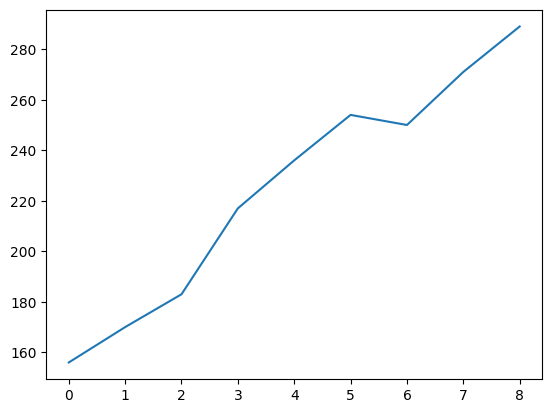

In [11]:
# Массив будет заполнен правильно спрогнозированными наблюдениями
predicted_correct = []
for i in range(1,10): # Перебор первых 10 обнаруженных главных компонент
    model = PCA(n_components = i) # Создание экземпляра модели PCA с разным количеством компонентов
    results = model.fit(x1) # Подгонка модели PCA по х=переменным
    Z = results.transform(x1) # Z содержит результат в форме матрицы
    fit = gnb.fit(Z,y1) # Применение наивного классификатора Байеса с гауссовым распределением для оценки
    pred = fit.predict(Z) # Собственно прогнозирование с использованием подогнанной модели
    # В конце каждой итерации добавляется новое количество правильно классифицированных наблюдений
    predicted_correct.append(int(confusion_matrix(pred,y1).trace()))
    print(predicted_correct) # Выводя этот массив, видно добавление новых наблюдений
plt.plot(predicted_correct) # Результат в графической форме
plt.show() # Вывод графика

[156, 170, 183, 217, 236, 254, 250, 271, 289, 298, 307]


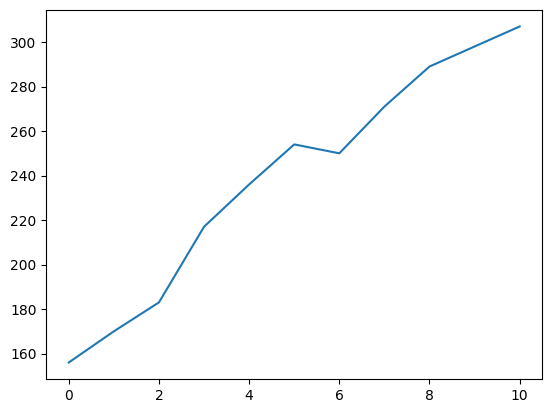

In [12]:
# То же для всех 11 компонент (рис. 2.38): диапазон расширен до range(1, 12)
predicted_correct = []
for i in range(1,12):
    model = PCA(n_components = i)
    results = model.fit(x1)
    Z = results.transform(x1)
    fit = gnb.fit(Z,y1)
    pred = fit.predict(Z)
    predicted_correct.append(int(confusion_matrix(pred,y1).trace()))
print(predicted_correct)
plt.plot(predicted_correct)
plt.show()

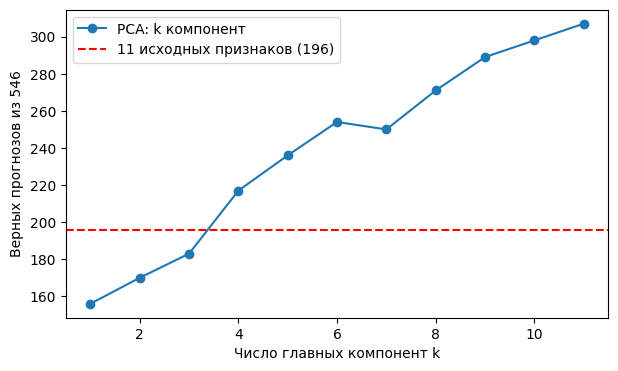

Первое k, при котором результат выше, чем на исходных признаках: 4
Доля верных прогнозов при k = 11: 56.2 %


In [13]:
# Дополнительно: тот же график с правильной осью (число компонент) и ориентиром — результатом на исходных признаках
plt.figure(figsize=(7, 4))
plt.plot(range(1, 12), predicted_correct, marker='o', label='PCA: k компонент')
plt.axhline(correct_raw, color='red', linestyle='--', label='11 исходных признаков (%d)' % correct_raw)
plt.xlabel('Число главных компонент k')
plt.ylabel('Верных прогнозов из %d' % len(y1))
plt.legend()
plt.show()

better = [k for k, c in zip(range(1, 12), predicted_correct) if c > correct_raw]
print('Первое k, при котором результат выше, чем на исходных признаках:', better[0] if better else 'нет')
print('Доля верных прогнозов при k = 11: %.1f %%' % (100 * predicted_correct[-1] / len(y1)))

**Результат и отличия от рис. 2.36–2.38.** Циклы выполнены так же, как на рис. 2.36; первый — для `range(1, 10)`, то есть для 1–9 компонент (рис. 2.37), второй — для `range(1, 12)`, то есть для 1–11 компонент (рис. 2.38). Отличия от методички:

- **Комментарий на рис. 2.36 неточен:** «перебор первых 10 компонент», а `range(1, 10)` даёт компоненты с 1-й по 9-ю (десятой нет). Рис. 2.37 в методичке подписан «9 скрытых переменных», то есть сама методичка выполняет именно 9. Для рис. 2.38 диапазон нужно расширить до `range(1, 12)`, что и сделано во второй ячейке.
- **Ось x на графиках методички смещена:** `plt.plot` берёт индекс списка, поэтому «0» на оси означает одну компоненту, «10» — одиннадцать. Дополнительный график строит ту же кривую с корректной осью k = 1…11 и линией для 11 исходных признаков.
- **Ещё один эффект, который методичка не упоминает.** При k = 11 PCA — это *поворот* пространства признаков без потери информации, и все 11 компонент содержат те же данные, что и 11 исходных признаков. Различие результатов (196 против ≈ 300 по методичке) обусловлено не «новой информацией», а тем, что наивный байесовский классификатор предполагает независимость признаков, а главные компоненты не коррелируют друг с другом, поэтому предположение выполняется лучше. Это объясняет рост «прогностической силы» при увеличении числа компонент и её превышение над исходными признаками.
- **`int(...)` вокруг `.trace()`.** В новых версиях NumPy список из значений `np.int64` печатается как `[np.int64(49), ...]`; преобразование в `int` возвращает вид `[49, ...]`, как на рисунках методички, и на расчёт не влияет.
- Все числа здесь — число точных совпадений цены **на обучающей выборке** (см. раздел 4), а не качество прогноза для новых объектов.

**Результат.** Массив `predicted_correct` для 1–11 компонент совпадает с рис. 2.37–2.38 методички: `[156, 170, 183, 217, 236, 254, 250, 271, 289, 298, 307]`.
- **Порог исходных признаков (196) превышается начиная с k = 4** (217), как и пишет методичка («с 4 скрытыми переменными лучше, чем с 11 исходными»).
- **Провал на рис. 2.37 приходится на k = 7** (250 против 254 при k = 6): на графике методички это индекс 6 (ось сдвинута на единицу).
- **При k = 11 — 307 верных прогнозов из 546, то есть 56,2 %.** В методичке «более 300, то есть 55 %» (300 / 546 ≈ 55 %), по факту 307 / 546 = 56,2 %.
- Прирост на последних компонентах меньше, чем на первых (с k = 9 до 11 всего +18, а с k = 3 до 4 +34), как и написано в методичке.

## 6. Проверка на отложенной выборке (дополнительно)

**Зачем этот раздел, если его нет в методичке.** Вывод методички — «добавление скрытых переменных сильно повышает прогностическую способность» — получен на тех же данных, на которых обучалась модель, и для точного совпадения цены. Ниже то же сравнение (исходные признаки и 1–11 компонент) выполняется на отложенной тестовой выборке (80/20, 10 разных разбиений). Стандартизация и PCA в этом случае подгоняются только по обучающей части (`Pipeline`), чтобы информация из тестовой части не просачивалась в модель. Кроме точного совпадения цены считается более осмысленный показатель — доля прогнозов, ошибающихся не более чем на 10 %.

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def holdout_scores(make_model, n_splits=10):
    exact, within10 = [], []
    for seed in range(n_splits):
        Xtr, Xte, ytr, yte = train_test_split(x1_raw, y1, test_size=0.2, random_state=seed)
        m = make_model().fit(Xtr, ytr)
        p = m.predict(Xte)
        exact.append((p == yte).mean())
        within10.append((abs(p - yte) / yte <= 0.10).mean())
    return np.mean(exact), np.mean(within10)

rows = {'11 исходных признаков': holdout_scores(lambda: make_pipeline(StandardScaler(), GaussianNB()))}
for k in range(1, 12):
    rows['PCA, k = %d' % k] = holdout_scores(lambda k=k: make_pipeline(StandardScaler(), PCA(n_components=k), GaussianNB()))

hold = pd.DataFrame(rows, index=['Точное совпадение цены, %', 'Ошибка не более 10 %, %']).T * 100
print(hold.round(1).to_string())
print()
print('Для сравнения, обучающая выборка (как в методичке), k = 11: %.1f %% точных совпадений' % (100 * predicted_correct[-1] / len(y1)))

                       Точное совпадение цены, %  Ошибка не более 10 %, %
11 исходных признаков                        0.6                     26.9
PCA, k = 1                                   1.5                     30.0
PCA, k = 2                                   1.8                     31.0
PCA, k = 3                                   1.2                     31.7
PCA, k = 4                                   1.2                     30.7
PCA, k = 5                                   1.5                     31.9
PCA, k = 6                                   1.4                     31.0
PCA, k = 7                                   1.3                     31.6
PCA, k = 8                                   1.5                     31.5
PCA, k = 9                                   1.8                     31.7
PCA, k = 10                                  1.9                     31.1
PCA, k = 11                                  1.5                     32.1

Для сравнения, обучающая выборка (как

**Результат.** На отложенной выборке картина иная, чем на обучающей:
- **Точное совпадение цены:** 0,6 % на исходных признаках и 1,2–1,9 % при любых k от 1 до 11 — против 35,9 % и 56,2 % на обучающих данных. Точно угадать цену на новых объектах модель практически не может, поэтому «прогностическая сила» методички — в основном результат запоминания обучающей выборки.
- **Доля прогнозов с ошибкой не более 10 %:** 26,9 % на исходных признаках и 30,0–32,1 % на компонентах. Небольшое преимущество PCA (≈ 3–5 процентных пунктов) сохраняется, потому что некоррелированные компоненты лучше подходят наивному байесовскому классификатору, но оно мало.
- **Зависимости от числа компонент практически нет:** с k = 1 (30,0 %) до k = 11 (32,1 %) прирост около 2 пунктов, что в пределах разброса между разбиениями. Вывод методички «добавление скрытых переменных сильно повышает прогностическую способность» на новых данных **не подтверждается**: на обучающей выборке рост от 156 до 307 вызван подгонкой.

## 7. Регрессия на главных компонентах (дополнительно)

**Зачем.** Задание формулируется как «объяснить показатель `sale price` с использованием разных характеристик», то есть цена — числовая переменная, и естественный способ оценить пользу PCA — регрессия на главных компонентах: сколько компонент достаточно, чтобы объяснять цену не хуже, чем 11 исходных признаков. R² считается кросс-валидацией (5 блоков), PCA и стандартизация подгоняются внутри каждого блока.

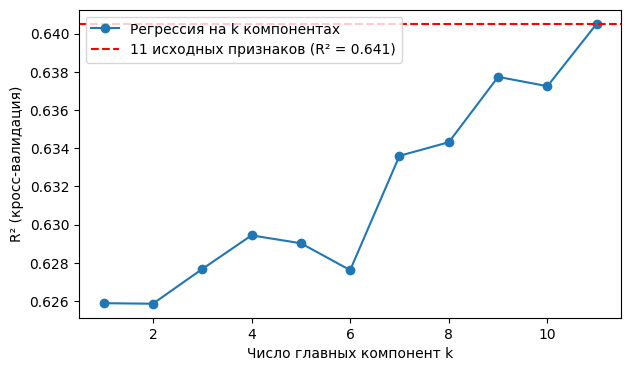

1     0.626
2     0.626
3     0.628
4     0.629
5     0.629
6     0.628
7     0.634
8     0.634
9     0.638
10    0.637
11    0.641
R² на 11 исходных признаках: 0.641
Лучшее k: 11 | минимальное k, при котором R² не хуже лучшего на 0.01: 7


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
r2_pcr = []
for k in range(1, 12):
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k), LinearRegression())
    r2_pcr.append(cross_val_score(pipe, x1_raw, y1, cv=cv, scoring='r2').mean())
r2_full = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), x1_raw, y1, cv=cv, scoring='r2').mean()

plt.figure(figsize=(7, 4))
plt.plot(range(1, 12), r2_pcr, marker='o', label='Регрессия на k компонентах')
plt.axhline(r2_full, color='red', linestyle='--', label='11 исходных признаков (R² = %.3f)' % r2_full)
plt.xlabel('Число главных компонент k')
plt.ylabel('R² (кросс-валидация)')
plt.legend()
plt.show()

print(pd.Series(r2_pcr, index=range(1, 12)).round(3).to_string())
print('R² на 11 исходных признаках:', round(r2_full, 3))
k_best = int(np.argmax(r2_pcr)) + 1
print('Лучшее k:', k_best, '| минимальное k, при котором R² не хуже лучшего на 0.01:', next(k for k, r in zip(range(1, 12), r2_pcr) if r >= max(r2_pcr) - 0.01))

**Результат.** R² кросс-валидации почти не зависит от числа компонент: 0,626 при k = 1, 0,629 при k = 4–5, 0,634 при k = 7–8, 0,641 при k = 11. Максимум достигнут при k = 11 и **совпадает с R² линейной регрессии на исходных признаках (0,641)** — это ожидаемо, потому что при k = 11 PCA лишь поворачивает оси. Различие между k = 1 и k = 11 равно 0,015, то есть первая главная компонента сама объясняет почти всё, что может объяснить линейная модель; значение согласуется с работой 2.3 (линейные модели ≈ 0,65–0,67 на тесте).

Причина: PC1 — это общий фактор «размер дома» (см. раздел 3), и её корреляция с ценой равна 0,80 (см. самостоятельную работу), то есть $R^2 \approx 0{,}80^2 \approx 0{,}64$. Остальные компоненты добавляют лишь около 0,015. Здесь PCA без учителя оказался удачным, потому что направление наибольшей дисперсии совпало с главным фактором цены; в общем случае так не бывает.

## Выводы по заданию

1. Данные стандартизированы (среднее 0, отклонение 1), и PCA построен на 11 признаках недвижимости. Первые 4 компоненты объясняют 57,1 % дисперсии, первые 5 — 65,2 %, первые 8 — 85,3 %; по критерию Кайзера значимых компонент 4.
2. Проценты из текста методички (25 %, 16 %, 13 % …) не соответствуют её рис. 2.33: первая компонента объясняет 21,33 %, вторая 13,91 %, третья 11,60 %. Утверждение «первые 5 переменных содержат большую часть информации» верно лишь частично (65 %).
3. PC1 — общий фактор «размер и благоустроенность дома» (все веса одного знака, `lot size`, `#bath`, `#bedroom`, `#stories`); её корреляция с ценой 0,80, PC2 с ценой почти не связана (−0,03).
4. Результаты методики воспроизведены: на исходных признаках 196 верных прогнозов из 546 (35,9 %), на 11 компонентах — 307 (56,2 %), превышение уровня исходных признаков начинается с 4 компонент.
5. Но эти показатели получены на обучающей выборке, и цена трактуется как категориальная переменная с 219 «классами» (108 из них встречаются один раз). На отложенной выборке точное совпадение цены составляет 0,6 % (исходные признаки) и 1,2–1,9 % (компоненты); с ошибкой не более 10 % — 27 % против 30–32 %. Рост «прогностической силы» при добавлении компонент — главным образом подгонка и следствие некоррелированности компонент для `GaussianNB`, а не новая информация (при k = 11 PCA — поворот осей).
6. Для объяснения цены как числовой переменной корректнее регрессия на компонентах: R² (5-кратная кросс-валидация) равен 0,626 уже при одной компоненте и 0,641 при всех 11 (как у регрессии на исходных признаках). Одна компонента PC1 даёт почти всё, что может дать линейная модель; сжатие 11 признаков до 1–4 компонент почти не снижает качество.
7. PCA не использует целевую переменную и не гарантирует, что компонента с большой дисперсией важна для цены. Здесь это совпало (PC1 связана с ценой), но в общем случае применять метод нужно для сжатия данных и устранения мультиколлинеарности, а не как способ повысить качество прогноза.

## Самостоятельная работа

Требуется: используя `Rural_prices.csv`, построить метод PCA, вывести процент объяснённой вариации для 11 компонент и визуализировать результат для первых двух компонент. Используется набор библиотек, заданный в методичке.

In [16]:
# Самостоятельная работа, шаг 1: библиотеки по методичке
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# В методичке самостоятельная работа начинается с исходной таблицы признаков x1;
# в ноутбуке x1 уже заменена стандартизованным массивом, поэтому возвращаем таблицу из x1_raw
x1 = x1_raw

In [17]:
# Шаг 2: стандартизировать данные
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x1)

In [18]:
# Шаг 3: применить PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [19]:
# Шаг 4: доли объяснённой дисперсии
explained_variance = pca.explained_variance_ratio_
print(f'Объясненная дисперсия первой главной компоненты: {explained_variance[0]:.2%}')
print(f'Объясненная дисперсия второй главной компоненты: {explained_variance[1]:.2%}')

Объясненная дисперсия первой главной компоненты: 21.33%
Объясненная дисперсия второй главной компоненты: 13.91%


In [20]:
# Шаг 4 (продолжение): доли объяснённой дисперсии для всех 11 компонент, как требует задание
pca_full = PCA(n_components=11)
pca_full.fit(X_scaled)
ratio_full = pca_full.explained_variance_ratio_

for i, r in enumerate(ratio_full, start=1):
    print(f'Компонента {i:2d}: {r:7.2%}   накопленная доля: {ratio_full[:i].sum():7.2%}')
print('Сумма долей 11 компонент:', f'{ratio_full.sum():.2%}')
print('Две первые компоненты в PCA(n_components=2) и PCA(n_components=11) совпадают:', np.allclose(explained_variance, ratio_full[:2]))
print('Результат стандартизации совпадает с x1 из основной части (повторная стандартизация ничего не меняет):', np.allclose(X_scaled, preprocessing.StandardScaler().fit_transform(x1_raw)))

Компонента  1:  21.33%   накопленная доля:  21.33%
Компонента  2:  13.91%   накопленная доля:  35.24%
Компонента  3:  11.60%   накопленная доля:  46.84%
Компонента  4:  10.26%   накопленная доля:  57.09%
Компонента  5:   8.08%   накопленная доля:  65.17%
Компонента  6:   7.51%   накопленная доля:  72.69%
Компонента  7:   6.71%   накопленная доля:  79.40%
Компонента  8:   5.92%   накопленная доля:  85.32%
Компонента  9:   5.70%   накопленная доля:  91.02%
Компонента 10:   5.21%   накопленная доля:  96.23%
Компонента 11:   3.77%   накопленная доля: 100.00%
Сумма долей 11 компонент: 100.00%
Две первые компоненты в PCA(n_components=2) и PCA(n_components=11) совпадают: True
Результат стандартизации совпадает с x1 из основной части (повторная стандартизация ничего не меняет): True


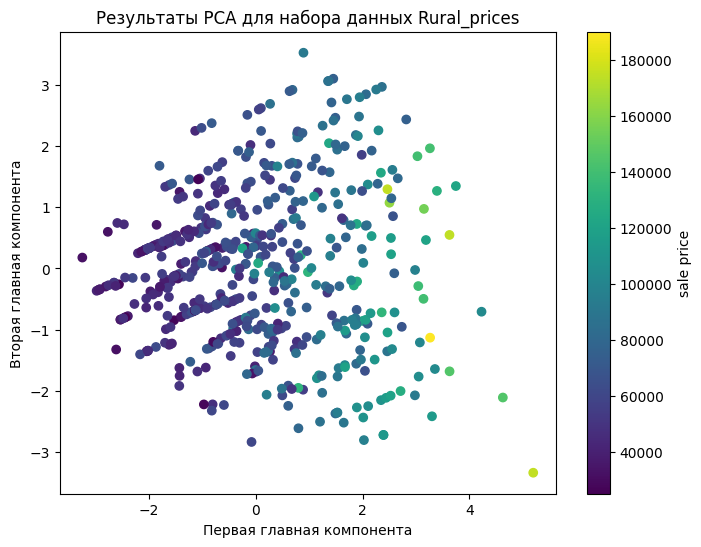

In [21]:
# Шаг 5: визуализация результатов PCA для двух первых компонент
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y1, cmap='viridis')
plt.colorbar().set_label('sale price')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Результаты PCA для набора данных Rural_prices')
plt.show()

In [22]:
# Дополнительно: связь компонент с ценой
print('Корреляция PC1 с ценой: %.3f' % np.corrcoef(X_pca[:, 0], y1)[0, 1])
print('Корреляция PC2 с ценой: %.3f' % np.corrcoef(X_pca[:, 1], y1)[0, 1])
print('Доля дисперсии, объяснённая двумя компонентами вместе: %.2f %%' % (100 * explained_variance.sum()))

Корреляция PC1 с ценой: 0.799
Корреляция PC2 с ценой: -0.025
Доля дисперсии, объяснённая двумя компонентами вместе: 35.24 %


**Отличия от методички и обоснование.**

- **Противоречие в самом задании.** Условие требует вывести доли для 11 компонент, а код методички строит `PCA(n_components=2)`, и `explained_variance_ratio_` в нём содержит всего два значения, выводятся только они. Поэтому код шагов 2–5 выполнен без изменений, а для выполнения условия добавлена ячейка с `PCA(n_components=11)`: она печатает все 11 долей и накопленную сумму (сумма всех компонент — 100 %). Проверка в той же ячейке подтверждает, что первые две доли в двух вариантах совпадают: главные компоненты не зависят от того, сколько из них запрошено.
- **Исходная таблица `x1`.** В основной части работы `x1` заменена стандартизованным массивом, а самостоятельная работа в методичке стартует с исходной таблицы, поэтому первая ячейка возвращает `x1 = x1_raw`. Повторная стандартизация уже стандартизированных данных их не меняет (проверка в ячейке выше), так что результат от выбора совпадает.
- **Подпись цветовой шкалы.** Методичка оставляет её пустой (`set_label('')`), чтобы читатель понимал, что показывает цвет, подпись заменена на `sale price`.
- **Объект раскраски.** Цвет точки — цена `y1`, поэтому видно, как цена связана с положением объекта в плоскости двух первых компонент.

**Результат.** Первая компонента объясняет 21,33 % дисперсии, вторая — 13,91 %, вместе 35,24 % (в методичке ожидается ≈ 21 % и ≈ 14 %, значения совпали). Все 11 долей: 21,33; 13,91; 11,60; 10,26; 8,08; 7,51; 6,71; 5,92; 5,70; 5,21; 3,77 %, накопленная сумма равна 100 %. На диаграмме рассеяния цвет (цена) меняется вдоль первой компоненты: слева — дешёвые объекты (тёмные точки), справа — дорогие (зелёные и жёлтые); вдоль второй компоненты закономерности нет. Это подтверждают корреляции: PC1 с ценой 0,80, PC2 — −0,03.

Двумя компонентами объясняется лишь около трети дисперсии (35,24 %), поэтому плоскость двух компонент — сильное упрощение: на диаграмме видна только часть структуры, и перекрытие цветов не означает, что цена не зависит от признаков.

## Ответы на вопросы для самоконтроля

1. **Назначение метода главных компонент:** преобразовать набор коррелирующих признаков в меньшее число некоррелированных линейных комбинаций (главных компонент), сохраняющих максимум дисперсии, — для снижения размерности, выявления скрытых переменных и устранения мультиколлинеарности.
2. **Как вычисляется прогностическая сила:** в методичке — как число правильно классифицированных наблюдений, то есть сумма диагональных элементов (след) матрицы несоответствий; делённая на 546, она даёт долю верных прогнозов (196 / 546 ≈ 35,9 %). Эта величина считается на обучающей выборке.
3. **Роль наивного байесовского классификатора:** он не является частью самого PCA; он служит «измерительным инструментом» — по его точности сравнивается качество прогноза на исходных признаках и на разном числе компонент.
4. **Для чего применялось гауссово распределение:** `GaussianNB` моделирует распределение каждого признака внутри каждого класса нормальным распределением и по нему оценивает вероятность класса.
5. **Признак усиления прогностической силы:** рост числа верно классифицированных наблюдений (следа матрицы несоответствий) при добавлении новых компонент; на графике это возрастающая кривая. Важно, что на обучающих данных такой рост частично отражает подгонку, а не обобщающую способность (раздел 6).

## Итоги сверки с методичкой

| Что | В методичке | Реальные значения / комментарий |
|---|---|---|
| Стандартизация (рис. 2.31) | `StandardScaler`, формула (2.4) | совпадает; среднее 0, отклонение 1 (проверка в ячейке) |
| Ось графика каменистой осыпи | «объяснённая вариация», по тексту — проценты | собственные значения (сумма 11,02); проценты — `explained_variance_ratio_` |
| Доли компонент в тексте | 25, 16, 13, 12, 9, 8, 7,5, 7 % | не согласуются с рис. 2.33 методички (первая ≈ 21 %); наш запуск: 21,33; 13,91; 11,60; 10,26; 8,08 … |
| Названия столбцов в таблице компонент | задаются списком вручную | добавлена проверка порядка по `feature_names` |
| Прогноз на исходных признаках (рис. 2.34–2.35) | 196 из 546 (35,9 %) | 196 из 546 (35,9 %) — совпадает; цена трактуется как 219 классов (108 из них встречаются один раз), оценка на обучающей выборке |
| Цикл по компонентам (рис. 2.36) | комментарий «первые 10», `range(1, 10)` | 9 компонент; для 11 компонент использован `range(1, 12)` |
| Прогностическая сила при k = 11 (рис. 2.38) | > 300 (≈ 55 %) | 307 из 546 (56,2 %) — совпадает; рост с k = 4 выше уровня исходных признаков (217 > 196), провал при k = 7 |
| Оценка на отложенной выборке | не выполняется | добавлена (раздел 6), точное совпадение цены 0,6–1,9 % (вместо 36–56 % на обучающей); с ошибкой ≤ 10 % — 27 % (исходные) и 30–32 % (компоненты) |
| Регрессия на компонентах | не рассматривается | добавлена (раздел 7): R² (CV) 0,626 при k = 1, 0,641 при k = 11 = регрессия на исходных признаках |
| Самостоятельная работа | 11 компонент по условию, `n_components=2` в коде | шаги 2–5 выполнены как в методичке, для 11 долей добавлена `PCA(n_components=11)` |